# Customer repurchase modeling

Compare logistic and tree models using chronological validation. Earlier sections
show the log-loss experiments; the final experiment selects XGBoost by temporal
CV ROC-AUC, selects a policy threshold on development data, and evaluates both on
test. Test data does not select models, parameters, calibration or thresholds.

In [1]:
from pathlib import Path
from importlib import import_module, reload

import matplotlib.pyplot as plt
import pandas as pd

for name in ("preprocessing", "metrics", "baseline"):
    module = reload(import_module(f"online_retail.modeling.{name}"))
run_baseline = module.run_baseline
plot_calibration = module.plot_calibration

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/processed"
OUTPUT = ROOT / "artifacts/logistic_baseline"


from online_retail.modeling.tracking import TrackingConfig
from online_retail.modeling.workflows import run_training, import_results
TRACKING = TrackingConfig.local(ROOT)

## Data and class balance

Rows are customer-week snapshots. Each row uses past-only features and a fully
observed 50-day outcome. Class 1 = purchase in days 0–49; class 0 = no
purchase during that interval. Keep the observed proportions; do not rebalance this baseline.


In [2]:
train = pd.read_parquet(DATA / "train.parquet")
counts = train["RepurchaseWithin50Days"].value_counts().reindex([0, 1], fill_value=0)
pd.DataFrame({"snapshots": counts, "share_pct": counts / len(train) * 100}).round(2)


,snapshots,share_pct
RepurchaseWithin50Days,,
0,55824,60.47
1,36495,39.53


## Repeated snapshots and evaluation

Many weekly rows belong to the same customer. Adjacent feature histories and 50-day
outcomes overlap, so row count overstates independent information. Longer-observed
customers contribute more rows. Repetition does not automatically imply overfitting.

Keep weekly scoring for now. Use expanding date-based folds with training labels
mature before validation starts; never randomly split rows. L2 regularization limits
coefficient growth. Compare training and later validation losses, recognizing that
a gap can reflect time drift as well as overfitting. Do not use independent-row
confidence intervals. A later sensitivity check can thin training cutoffs to every
fourth week while leaving evaluation dates unchanged; no cadence change is made now.


In [3]:
pd.Series({
    "training_snapshots": len(train),
    "distinct_customers": train["Customer ID"].nunique(),
    "scoring_weeks": train["cutoff"].nunique(),
    "median_snapshots_per_customer": train.groupby("Customer ID").size().median(),
})


training_snapshots               92319.0
distinct_customers                3687.0
scoring_weeks                       33.0
median_snapshots_per_customer       31.0
dtype: float64

## Fit the baseline

Use 22 original behavioral/calendar predictors, excluding derived RFM scores/segment.
Imputation, predefined log1p count/spend transforms and scaling fit inside each fold.
The three internal validation windows cover July, August and September–October 2010;
training requires cutoff + 50 days <= validation start. Then fit initial training
and assess the separate December–March validation period. Final refit/test stay unused.


In [4]:
baseline = run_training("baseline", DATA, OUTPUT, TRACKING)
baseline["cv_metrics"].round(4)


,fold,model,train_log_loss,log_loss,weekly_log_loss,brier_score,accuracy,balanced_accuracy,macro_f1
0,1,logistic_l2,0.5989,0.5354,0.5354,0.1777,0.7387,0.6528,0.6617
1,1,prior,0.6832,0.6577,0.6577,0.2324,0.6604,0.5000,0.3977
2,2,logistic_l2,0.5862,0.5964,0.5958,0.2000,0.7159,0.6370,0.6353
3,2,prior,0.6783,0.6634,0.6633,0.2352,0.6290,0.5000,0.3861
4,3,logistic_l2,0.5694,0.7196,0.7186,0.2443,0.6565,0.6131,0.5870
5,3,prior,0.6705,0.6878,0.6877,0.2473,0.5658,0.5000,0.3614


In [5]:
# Probability metrics are primary; argmax classification metrics are diagnostic only.
baseline["validation_metrics"].round(4)


,model,log_loss,weekly_log_loss,brier_score,accuracy,balanced_accuracy,macro_f1
0,prior,0.6001,0.5999,0.2041,0.7717,0.5000,0.4356
1,logistic_l2,0.6769,0.6783,0.2294,0.6682,0.7005,0.6301


## Probability calibration

Points close to the diagonal indicate agreement between predicted probabilities
and observed class frequencies. This is a diagnostic using validation data, not a
fitted recalibration. Weekly observations are correlated. Compare log loss and Brier
with the prior reference before adding a more complex model.


This plot groups predictions into ten approximately equal-sized probability bins.
For each bin, compare mean predicted purchase probability (x) with observed purchase
fraction (y). For example, predictions averaging 0.7 should correspond to purchases
about 70% of the time. The diagonal represents agreement. We inspected calibration;
we did **not** fit sigmoid, isotonic or any other probability recalibration.

In [6]:
plot_calibration(baseline["validation_predictions"])
plt.show()


/tmp/ipykernel_373657/3995842565.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Baseline results are saved under `artifacts/logistic_baseline/`. Subsequent
sections add elastic net, tree tuning and finally the frozen-policy experiment.

**Initial finding.** On external validation, the binary logistic baseline has log loss
0.677 and Brier score 0.229, versus 0.600 and 0.204 for the prior reference (lower
is better). Balanced accuracy improves to 0.701 versus 0.500, but probability quality
does not improve. The validation non-purchase share is 77.2%, compared with 60.5%
in training, so outcome prevalence changes substantially over time.

## Elastic-net logistic regression

Next, compare six regularization settings using the same three expanding temporal
folds and 50-day maturity gap. Preprocessing is fitted anew in every fold. Select
by mean weekly log loss within training, then assess the later validation period.
This small explicit search keeps this first comparison easy to inspect; it is not
Optuna. Tree models follow after reviewing this result. Campaign thresholds do not
participate in model selection.

In [ ]:
elastic = run_training("elastic_net", DATA, ROOT / "artifacts/logistic_elastic_net", TRACKING)
elastic["candidate_metrics"].round(4)

In [ ]:
pd.concat([baseline["validation_metrics"], elastic["validation_metrics"]],
          ignore_index=True).round(4)

In [ ]:
plot_calibration(elastic["validation_predictions"])
plt.show()

## Binary campaign cost definition

Let action 1 mean contact and action 0 mean no contact. The true target is
purchase (1) versus no purchase (0). Define four costs:

| Actual outcome | No contact | Contact |
|---|---:|---:|
| No purchase (0) | c00 | c01 |
| Purchase (1) | c10 | c11 |

For threshold t, contact if p(purchase) >= t. Total cost is
`TN*c00 + FP*c01 + FN*c10 + TP*c11`.
Spending alone (contact costs £10, no contact £0) always favors contacting nobody.
A missed-opportunity cost or benefit assumption is needed for meaningful policy
optimization. The final experiment below supplies illustrative values and selects a threshold.
Select a threshold on policy-validation data and assess it on untouched later data.
These observed purchase labels do not measure incremental campaign response.
The final policy holdout is development data, separate from the model-fitting rows.

### First elastic-net result

The executed search gives validation log loss **0.662**, versus **0.677** for L2
and **0.600** for the prior reference. Brier score is **0.227**, versus **0.229**
and **0.204**, respectively. Elastic net improves slightly on L2 but still does not
beat the prior on probability quality. Saved candidate/fold tables are under
`artifacts/logistic_elastic_net/`.

An extra penalty for contacted non-buyers belongs in c01 (false positives), in
addition to campaign spend. Monetary values are still unspecified. Use
`online_retail.modeling.policy.campaign_cost` with an explicit 2x2 matrix to
evaluate a chosen policy; no threshold has been optimized.

## Tree models: temporal Optuna search

Optimize **mean weekly log loss** over all internal validation weeks. This scores
probabilities before choosing campaign thresholds. Week counts weight fold means;
pooled log loss is reported separately. Each model gets 15 seeded Optuna trials.
Every trial uses the same three expanding folds and 50-day label-maturity rule.
Imputation is learned inside each fold; trees use original scales and exclude the
same derived RFM columns as logistic models. Depth/leaf constraints and boosting
penalties control complexity. No cost optimization or class rebalancing.

Log loss: [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).

CV selects parameters using training only. December–March validation compares the
selected models. Test is reserved for final evaluation. This is an initial search,
not an exhaustive optimization.

In [2]:
tree_metrics = run_training("trees", DATA, ROOT / "artifacts/tree_models", TRACKING,
                            n_trials=15, objective_metric="weekly_log_loss")
tree_metrics.round(4)

,model,log_loss,weekly_log_loss,brier_score,accuracy,balanced_accuracy,macro_f1,roc_auc,average_precision,macro_precision,...,class_0_precision,class_0_recall,class_0_f1,class_1_precision,class_1_recall,class_1_f1,tn,fp,fn,tp
0,lightgbm,0.5642,0.5645,0.1888,0.7442,0.7157,0.6823,0.7879,0.5926,0.6718,...,0.8852,0.7681,0.8225,0.4584,0.6632,0.5421,44816,13528,5814,11450
1,xgboost,0.5583,0.5585,0.1861,0.7524,0.7145,0.6867,0.7869,0.5910,0.6756,...,0.8818,0.7843,0.8302,0.4694,0.6448,0.5433,45760,12584,6133,11131
2,random_forest,0.5510,0.5513,0.1826,0.7580,0.7140,0.6898,0.7879,0.5920,0.6786,...,0.8798,0.7950,0.8353,0.4775,0.6330,0.5443,46385,11959,6336,10928


### Compare probability quality and classification diagnostics

Classification metrics use a fixed argmax decision (approximately 0.5), without
threshold tuning. F2 weights recall more than F1. Micro precision/recall/F1 equal
accuracy for this task; balanced accuracy is mean class recall. ROC-AUC and average
precision measure ranking, rather than calibrated probability quality.

In [3]:
from online_retail.modeling.metrics import evaluate

reports = []
for name, directory in [("logistic_l2", ROOT / "artifacts/logistic_baseline"),
                        ("logistic_elastic_net", ROOT / "artifacts/logistic_elastic_net")]:
    predictions = pd.read_parquet(directory / "validation_predictions.parquet")
    reports.append({"model": name, **evaluate(
        predictions, predictions[["p_class_0", "p_class_1"]].to_numpy())})

# Recompute the prior reference with the expanded metric report.
validation = pd.read_parquet(DATA / "validation.parquet")
prior = train["RepurchaseWithin50Days"].mean()
prior_probabilities = [[1 - prior, prior]] * len(validation)
reports.append({"model": "prior", **evaluate(validation, prior_probabilities)})
comparison = pd.concat([pd.DataFrame(reports), tree_metrics], ignore_index=True)
comparison.to_csv(ROOT / "artifacts/model_comparison.csv", index=False)
comparison.round(4).T

,0,1,2,3,4,5
model,logistic_l2,logistic_elastic_net,prior,lightgbm,xgboost,random_forest
log_loss,0.6769,0.6618,0.6001,0.5642,0.5583,0.551
weekly_log_loss,0.6783,0.6631,0.5999,0.5645,0.5585,0.5513
brier_score,0.2294,0.2271,0.2041,0.1888,0.1861,0.1826
accuracy,0.6682,0.6663,0.7717,0.7442,0.7524,0.758
balanced_accuracy,0.7005,0.701,0.5,0.7157,0.7145,0.714
macro_f1,0.6301,0.629,0.4356,0.6823,0.6867,0.6898
roc_auc,0.7808,0.7821,0.5,0.7879,0.7869,0.7879
average_precision,0.587,0.5884,0.2283,0.5926,0.591,0.592
macro_precision,0.6427,0.6428,0.3858,0.6718,0.6756,0.6786


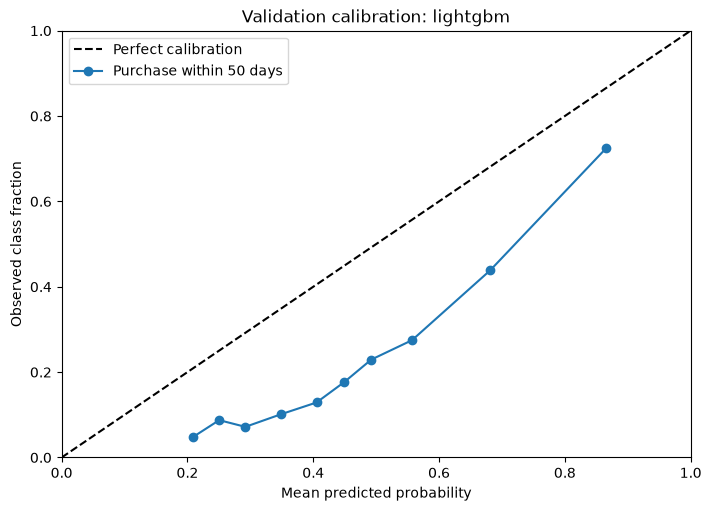

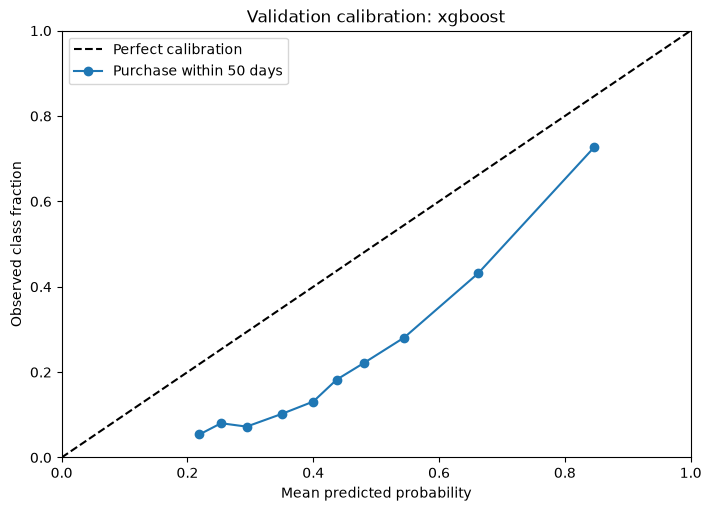

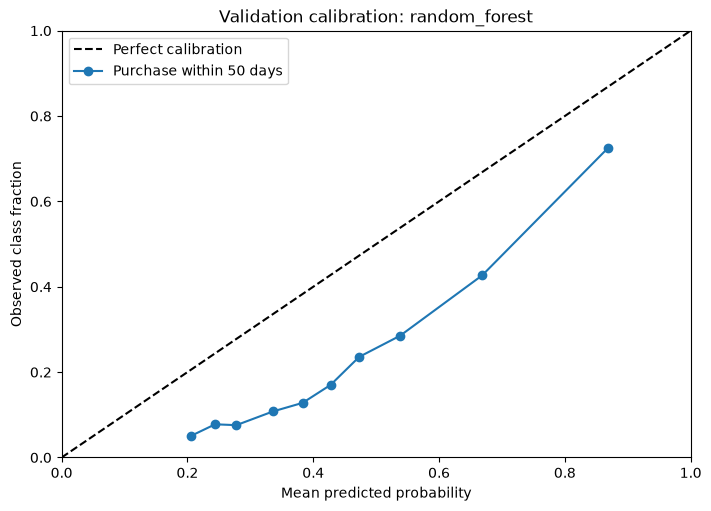

In [4]:
for name in ("lightgbm", "xgboost", "random_forest"):
    predictions = pd.read_parquet(
        ROOT / "artifacts/tree_models" / name / "validation_predictions.parquet")
    fig, ax = plot_calibration(predictions)
    ax.set_title(f"Validation calibration: {name}")
    plt.show()

In [5]:
# Every trial/fold metric is retained, not only the winning objective.
trial_reports = pd.concat([
    pd.read_csv(ROOT / "artifacts/tree_models" / name / "cv_metrics.csv").assign(model=name)
    for name in ("lightgbm", "xgboost", "random_forest")
], ignore_index=True)
trial_reports.groupby(["model", "trial"])[
    ["log_loss", "weekly_log_loss", "brier_score", "roc_auc", "average_precision",
     "balanced_accuracy", "class_1_precision", "class_1_recall"]
].mean().round(4)
# These are equal-fold summaries. Optuna's objective weights fold means by week count.

log_loss  weekly_log_loss  brier_score  roc_auc  \
model         trial                                                    
lightgbm      0        0.5849           0.5847       0.1983   0.7405   
              1        0.5763           0.5762       0.1953   0.7467   
              2        0.5829           0.5827       0.1976   0.7420   
              3        0.5798           0.5796       0.1965   0.7431   
              4        0.5933           0.5932       0.2012   0.7344   
              5        0.5796           0.5795       0.1964   0.7446   
              6        0.5759           0.5757       0.1950   0.7470   
              7        0.5803           0.5802       0.1966   0.7443   
              8        0.5972           0.5970       0.2024   0.7319   
              9        0.5801           0.5799       0.1965   0.7444   
              10       0.5756           0.5755       0.1951   0.7469   
              11       0.5756           0.5754       0.1951   0.7470   
              12       0.5761           0.5759       0.1952   0.7472   
              13       0.5766           0.5764       0.1953   0.7467   
              14       0.5769           0.5767       0.1958   0.7459   
random_forest 0        0.5774           0.5772       0.1956   0.7457   
              1        0.5839           0.5838       0.1990   0.7410   
              2        0.5765           0.5763       0.1955   0.7464   
              3        0.5780           0.5778       0.1962   0.7458   
              4        0.5826           0.5825       0.1985   0.7419   
              5        0.5767           0.5766       0.1954   0.7455   
              6        0.5762           0.5760       0.1953   0.7465   
              7        0.5777           0.5776       0.1963   0.7457   
              8        0.5800           0.5798       0.1964   0.7437   
              9        0.5841           0.5840       0.1991   0.7409   
              10       0.5754           0.5753       0.1950   0.7467   
              11       0.5750           0.5749       0.1949   0.7472   
              12       0.5752           0.5750       0.1949   0.7471   
              13       0.5757           0.5755       0.1951   0.7465   
              14       0.5762           0.5761       0.1953   0.7463   
xgboost       0        0.6237           0.6235       0.2099   0.7244   
              1        0.5786           0.5784       0.1960   0.7433   
              2        0.5892           0.5890       0.1997   0.7369   
              3        0.5822           0.5820       0.1973   0.7424   
              4        0.5987           0.5985       0.2027   0.7326   
              5        0.5760           0.5758       0.1952   0.7456   
              6        0.5763           0.5761       0.1952   0.7468   
              7        0.5763           0.5762       0.1952   0.7469   
              8        0.5817           0.5816       0.1971   0.7418   
              9        0.5759           0.5758       0.1951   0.7463   
              10       0.5763           0.5761       0.1955   0.7464   
              11       0.5779           0.5778       0.1959   0.7437   
              12       0.5764           0.5763       0.1953   0.7467   
              13       0.5759           0.5758       0.1952   0.7465   
              14       0.5762           0.5761       0.1954   0.7463   

                     average_precision  balanced_accuracy  class_1_precision  \
model         trial                                                            
lightgbm      0                 0.6711             0.6663             0.6608   
              1                 0.6777             0.6694             0.6723   
              2                 0.6734             0.6666             0.6614   
              3                 0.6754             0.6683             0.6686   
              4                 0.6657             0.6659             0.6514   
              5                 0.6759             0.6693             0.6692

### Initial interpretation

On the later validation period, Random Forest has log loss **0.551** and Brier
**0.183**, XGBoost **0.558 / 0.186**, and LightGBM **0.564 / 0.189**. All improve
on the prior reference (**0.600 / 0.204**) and both logistic models. The differences
between trees are modest and are not a statistical significance claim.

Random Forest's accuracy is **0.758**, below the prior's **0.772**, while its balanced
accuracy is **0.714**, above **0.500**. This illustrates why accuracy alone would
favor the majority-class reference despite its worse probability quality. At the
diagnostic threshold, purchase precision is **0.477** and recall **0.633**.

These are validation results, not final test estimates. Search is limited to 15
trials per tree model. Review temporal stability and calibration before final
selection. No campaign threshold, cost policy or calibration model was optimized.

## Current experiment: optimize ROC-AUC, then freeze a campaign policy

Re-run the three tree searches with **mean weekly ROC-AUC** as the Optuna objective.
The temporal folds and 50-day maturity gap remain unchanged. Choose the model family
by its best internal-CV score. Validation tables remain diagnostic.

Illustrative costs (£ per customer-week), rows actual outcome and columns action:

| Actual outcome | No contact | Contact |
|---|---:|---:|
| No purchase | 0 | 15 |
| Purchase | 25 | 10 |

Contact costs £10, with £5 additional penalty for contacting a non-buyer. Missing a
buyer costs £25. These assumptions do not estimate incremental campaign profit.
The probability threshold is selected after refitting on later policy data.

Reserve the last six refit weeks (March 7–April 11) for policy selection. Final fit
uses snapshots with labels mature before March 7 (through January 10). This cannot
use every refit row: policy data and the label-maturity gap must be excluded.
Keep the model fixed after threshold selection. Earlier development validation
partly overlaps the policy period; only final test is the final held-out estimate.

In [2]:
import json
from online_retail.modeling.final import run_final, plot_policy_cost

AUC_OUTPUT = ROOT / "artifacts/roc_auc_models"
FINAL_OUTPUT = ROOT / "artifacts/final_roc_policy"
# Saved searches make rerunning the notebook inexpensive. Set True to rerun tuning.
RERUN_AUC_SEARCH = False
if RERUN_AUC_SEARCH or not all((AUC_OUTPUT / name / "run.json").exists()
    for name in ("lightgbm", "xgboost", "random_forest")):
    run_training("trees", DATA, AUC_OUTPUT, TRACKING, n_trials=15,
                 objective_metric="weekly_roc_auc")

auc_selection = pd.DataFrame([
    {"model": name, **json.loads((AUC_OUTPUT / name / "run.json").read_text())}
    for name in ("lightgbm", "xgboost", "random_forest")])
auc_selection[["model", "best_cv_value", "n_trials"]].sort_values(
    "best_cv_value", ascending=False)

,model,best_cv_value,n_trials
1,xgboost,0.744442,15
2,random_forest,0.744246,15
0,lightgbm,0.744124,15


In [3]:
# Freeze selected model and policy before opening test; load existing final report on rerun.
if (FINAL_OUTPUT / "report.json").exists():
    final_report = json.loads((FINAL_OUTPUT / "report.json").read_text())
else:
    final_report = run_final(DATA, AUC_OUTPUT, FINAL_OUTPUT)
pd.Series({k: final_report[k] for k in ["model", "threshold", "fit_last_cutoff",
    "policy_first_cutoff", "policy_last_cutoff"]})

model                              xgboost
threshold                             0.62
fit_last_cutoff        2011-01-10 00:00:00
policy_first_cutoff    2011-03-07 00:00:00
policy_last_cutoff     2011-04-11 00:00:00
dtype: object

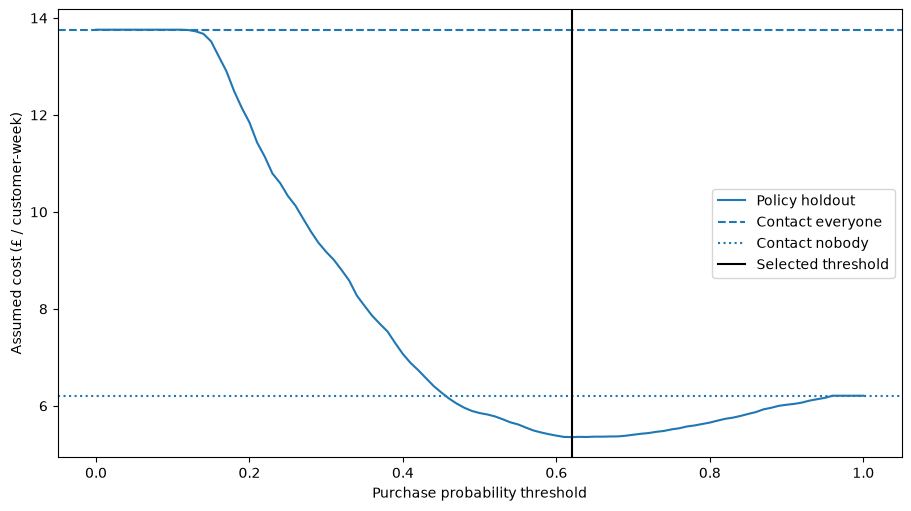

In [4]:
plot_policy_cost(FINAL_OUTPUT)
plt.show()

### Test evaluation A: ranking and probability quality

ROC-AUC and average precision evaluate ranking across thresholds. Average precision
summarizes precision–recall behaviour; it is not the trapezoidal area under the PR
curve. Log loss and Brier score evaluate probability quality without a classification
threshold. Weekly log loss weights each week equally. No parameters or decisions
are chosen using any of these test results.

In [ ]:
# Threshold-agnostic test evaluation: use saved predictions/results, no selection.
probability_metrics = ["roc_auc", "average_precision", "log_loss", "weekly_log_loss", "brier_score"]
probability_test_report = pd.Series(final_report["test_probability_and_05_metrics"])[
    probability_metrics].rename("test_value").to_frame()
probability_test_report.round(4)

,test_value
roc_auc,0.7948
average_precision,0.6504
log_loss,0.5098
weekly_log_loss,0.5088
brier_score,0.1673


### Test evaluation B: frozen development threshold

The threshold **0.62** was selected on March–April **policy-holdout** outcomes after
refitting the model. This is development data, not the final test and not the rows
used to fit this model. We now apply that exact threshold to test probabilities and
report cost, contact count, confusion counts and precision/recall/F1. No test cost
curve is used to choose a different threshold. The cost plot above uses policy data.
The 0.5 metrics retained in the JSON report are separate diagnostics.

In [ ]:
# Evaluate the previously frozen threshold. No test threshold search.
policy_test_report = pd.Series({
    "threshold_from_policy_holdout": final_report["threshold"],
    **{k: final_report["test_policy"][k] for k in ["mean_cost", "total_cost", "contacts", "accuracy"]},
    "contact_none_mean_cost": final_report["test_contact_none_mean_cost"],
    "contact_all_mean_cost": final_report["test_contact_all_mean_cost"],
}).rename("test_value").to_frame()
policy_test_report.round(4)

,test_value
threshold_from_policy_holdout,0.6200
mean_cost,5.7657
total_cost,599830.0000
contacts,16826.0000
accuracy,0.7962
contact_none_mean_cost,6.7733
contact_all_mean_cost,13.6453


In [ ]:
pd.DataFrame(final_report["test_policy"]["classification_report"]).T

,precision,recall,f1-score,support
0,0.813331,0.935147,0.869996,75848.00000
1,0.707655,0.422444,0.529059,28186.00000
accuracy,0.796240,0.796240,0.796240,0.79624
macro avg,0.760493,0.678795,0.699527,104034.00000
weighted avg,0.784700,0.796240,0.777625,104034.00000


### Frozen-policy test interpretation

XGBoost wins internal CV (mean weekly ROC-AUC **0.74444**), narrowly ahead of
Random Forest (**0.74425**) and LightGBM (**0.74412**). The policy holdout chooses
threshold **0.62**; this is frozen before loading test.

On test, ROC-AUC is **0.7948**, average precision **0.6504**, log loss **0.5098**,
and Brier score **0.1673**. At the selected policy threshold, buyer precision is
**0.7077**, recall **0.4224**, and accuracy **0.7962**. This differs from the
separately reported 0.5 diagnostic metrics.

Assumed test cost is **£5.77 per customer-week**, versus **£6.77** for contacting
nobody and **£13.65** for contacting everybody, about **14.9%** lower than the
no-contact reference. This is decision loss under invented costs, not measured
campaign ROI. The model contacts 16,826 of 104,034 customer-week instances; these
are not 16,826 distinct people. No model or threshold was changed after test.

Final fitting uses 146,415 snapshots through January 10, 2011. The six policy
weeks contain 28,001 snapshots. Reserving this holdout and the maturity gap means
not every pre-test refit snapshot was used for model fitting.

## MLflow tracking

Fresh training calls above use the shared tracked workflow. Saved outputs can also
be imported without training or re-evaluating test. Imports are explicitly tagged
as historical artifacts; they record today's code/environment, not proof of the
original run's code revision. Model output in MLflow is two-column purchase
probabilities; the policy threshold remains a separate artifact.

Run the next cell only when you want an additional import run. See
[tracking guide](../docs/mlflow.md) for scripts and the local UI.

In [ ]:
IMPORT_SAVED_RESULTS = False
if IMPORT_SAVED_RESULTS:
    imported_run_id = import_results(FINAL_OUTPUT, DATA, TRACKING, name="frozen-xgboost-import")
    print(imported_run_id)